# 09 · All runs: summary table, which differences are real, and the best model (task T25)

The three ablation notebooks trained and scored the runs. This notebook brings all of them together:

1. check that every configuration has its three finished runs;
2. write the table of all runs (`results/all_runs.csv`, laid out like the tracker's Runs tab) and the per-config summary (`results/summary.csv`);
3. decide which differences are real, by comparing each gap with the spread between seeds;
4. quantify a second kind of uncertainty, the one that comes from having only 90 test chips and 15 Bolivia chips;
5. compare test with Bolivia (RQ4);
6. name the best U-Net by **validation** IoU, for the error analysis and the demo.

No model is trained or scored here; everything is read from `results/<run>/`.

In [1]:
import json
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
import src  # noqa: F401

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from src import analysis, make_figures, viz
from src.config import CONFIG_NAMES, STUDIES, runs_of

viz.use_style()
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
pd.set_option("display.width", 220)

## 1. Is everything there?

In [2]:
runs, summary = analysis.write_tables()
status = runs.groupby("Config", sort=False)["Status"].value_counts().unstack(fill_value=0)
display(status)
unfinished = runs[runs["Status"] != "Finished"]["Run ID"].tolist()
assert not unfinished, f"runs not finished: {unfinished}"
assert (summary.set_index("Config").loc[list(CONFIG_NAMES), "Finished runs"] == 3).all()
print(f"{len(runs)} runs finished: R00 and R00b (thresholds) and R01 to R21 (U-Nets). No run failed or had to be repeated.")

Status,Finished
Config,
Otsu (E0),1
Default,3
VH only,3
VV+VH,3
BCE loss,3
Dice loss,3
Scratch U-Net,3
MobileNetV2 + ImageNet,3
Tuned VH threshold,1


23 runs finished: R00 and R00b (thresholds) and R01 to R21 (U-Nets). No run failed or had to be repeated.


## 2. All runs

One row per run, in the column layout of the tracker's Runs tab (saved as `results/all_runs.csv`). IoU, precision, recall and F1 are pooled over all labelled pixels of the split.

In [3]:
runs[["Run ID", "Config", "Seed", "Val IoU (best)", "Test IoU", "Test precision", "Test recall", "Test F1", "Bolivia IoU",
      "Bolivia F1", "Epochs trained", "Sec per epoch", "Peak GPU memory (MB)"]].set_index("Run ID")

,Config,Seed,Val IoU (best),Test IoU,Test precision,Test recall,Test F1,Bolivia IoU,Bolivia F1,Epochs trained,Sec per epoch,Peak GPU memory (MB)
Run ID,,,,,,,,,,,,
R00,Otsu (E0),–,0.3880,0.4334,0.4827,0.8094,0.6047,0.6529,0.7900,NaN,NaN,NaN
R01,Default,0,0.6282,0.6681,0.8520,0.7558,0.8010,0.6547,0.7913,39.0000,8.6400,622.5000
R02,Default,1,0.6449,0.6640,0.8437,0.7571,0.7981,0.6213,0.7664,32.0000,8.4400,622.5000
R03,Default,2,0.6435,0.6674,0.8135,0.7880,0.8005,0.6347,0.7765,34.0000,8.5900,622.5000
R04,VH only,0,0.6054,0.6392,0.8459,0.7235,0.7799,0.6299,0.7729,39.0000,8.3000,611.1000
R05,VH only,1,0.6110,0.6265,0.8161,0.7295,0.7704,0.6027,0.7521,44.0000,8.3300,611.1000
R06,VH only,2,0.6205,0.6377,0.8261,0.7366,0.7788,0.6370,0.7782,47.0000,8.1600,611.1000
R07,VV+VH,0,0.6442,0.6682,0.8511,0.7567,0.8011,0.5885,0.7409,47.0000,8.2200,999.4000
R08,VV+VH,1,0.6455,0.6776,0.8438,0.7748,0.8078,0.6583,0.7939,54.0000,8.2300,614.0000


## 3. Mean ± standard deviation over the three seeds

In [4]:
cols = ["Val IoU (best)", "Test IoU", "Test precision", "Test recall", "Test mean per-chip IoU", "Bolivia IoU",
        "Bolivia precision", "Bolivia recall", "Bolivia mean per-chip IoU"]
s = summary.set_index("Config")
table = pd.DataFrame({c: [analysis.mean_std(a, b) for a, b in zip(s[f"{c} mean"], s[f"{c} std"])] for c in cols}, index=s.index)
table.insert(0, "Runs", s["Finished runs"])
table

,Runs,Val IoU (best),Test IoU,Test precision,Test recall,Test mean per-chip IoU,Bolivia IoU,Bolivia precision,Bolivia recall,Bolivia mean per-chip IoU
Config,,,,,,,,,,
Otsu (E0),1,0.388,0.433,0.483,0.809,0.260,0.653,0.731,0.859,0.442
Tuned VH threshold,1,0.492,0.524,0.747,0.637,0.279,0.531,0.870,0.577,0.322
Default,3,0.639 ± 0.009,0.667 ± 0.002,0.836 ± 0.020,0.767 ± 0.018,0.398 ± 0.012,0.637 ± 0.017,0.878 ± 0.020,0.699 ± 0.023,0.382 ± 0.004
VH only,3,0.612 ± 0.008,0.634 ± 0.007,0.829 ± 0.015,0.730 ± 0.007,0.358 ± 0.008,0.623 ± 0.018,0.889 ± 0.016,0.676 ± 0.030,0.382 ± 0.029
VV+VH,3,0.650 ± 0.009,0.670 ± 0.006,0.854 ± 0.013,0.757 ± 0.018,0.403 ± 0.004,0.632 ± 0.038,0.874 ± 0.005,0.696 ± 0.044,0.393 ± 0.021
BCE loss,3,0.616 ± 0.009,0.643 ± 0.011,0.853 ± 0.037,0.725 ± 0.016,0.372 ± 0.006,0.559 ± 0.120,0.891 ± 0.008,0.603 ± 0.141,0.338 ± 0.065
Dice loss,3,0.644 ± 0.007,0.660 ± 0.010,0.828 ± 0.011,0.765 ± 0.007,0.394 ± 0.003,0.624 ± 0.019,0.863 ± 0.012,0.693 ± 0.031,0.371 ± 0.008
Scratch U-Net,3,0.641 ± 0.009,0.655 ± 0.010,0.794 ± 0.001,0.790 ± 0.016,0.393 ± 0.017,0.671 ± 0.071,0.857 ± 0.017,0.759 ± 0.100,0.414 ± 0.058
MobileNetV2 + ImageNet,3,0.664 ± 0.007,0.662 ± 0.004,0.846 ± 0.002,0.752 ± 0.007,0.400 ± 0.004,0.519 ± 0.019,0.835 ± 0.019,0.579 ± 0.030,0.354 ± 0.014


## 4. Which differences are real?

The rule fixed in advance: a gap between two configs counts only if it is larger than the seed-to-seed standard deviation (the larger of the two configs' values). Welch's t-test is listed for reference; with three seeds per config it has little power.

In [5]:
gaps = pd.concat([analysis.gap_table(study, runs).assign(Study=study) for study in STUDIES], ignore_index=True)
gaps.to_csv(ROOT / "results" / "gaps.csv", index=False)
gaps.set_index(["Study", "Metric", "A", "B"])[["Mean A", "Mean B", "Gap (A - B)", "Larger std", "Gap / std", "Gap larger than std", "Welch p"]]

Mean A  Mean B  Gap (A - B)  Larger std  Gap / std  Gap larger than std  Welch p
Study Metric      A             B                                                                                                       
E1    Test IoU    VH only       VV+VH                   0.6345  0.6703      -0.0358      0.0069     5.1693                 True   0.0029
      Bolivia IoU VH only       VV+VH                   0.6232  0.6322      -0.0091      0.0381     0.2377                False   0.7358
      Test IoU    VH only       Default                 0.6345  0.6665      -0.0320      0.0069     4.6234                 True   0.0098
      Bolivia IoU VH only       Default                 0.6232  0.6369      -0.0137      0.0181     0.7573                False   0.3914
      Test IoU    VV+VH         Default                 0.6703  0.6665       0.0038      0.0065     0.5832                False   0.4232
      Bolivia IoU VV+VH         Default                 0.6322  0.6369      -0.0047      0.0381     0.1221                False   0.8600
E2    Test IoU    BCE loss      Dice loss               0.6433  0.6604      -0.0171      0.0108     1.5810                 True   0.1149
      Bolivia IoU BCE loss      Dice loss               0.5593  0.6237      -0.0644      0.1198     0.5375                False   0.4509
      Test IoU    BCE loss      Default                 0.6433  0.6665      -0.0232      0.0108     2.1461                 True   0.0601
      Bolivia IoU BCE loss      Default                 0.5593  0.6369      -0.0776      0.1198     0.6475                False   0.3786
      Test IoU    Dice loss     Default                 0.6604  0.6665      -0.0061      0.0100     0.6128                False   0.4005
      Bolivia IoU Dice loss     Default                 0.6237  0.6369      -0.0132      0.0190     0.6925                False   0.4205
E3    Test IoU    Scratch U-Net Default                 0.6554  0.6665      -0.0111      0.0103     1.0824                 True   0.1975
      Bolivia IoU Scratch U-Net Default                 0.6714  0.6369       0.0345      0.0706     0.4886                False   0.4892
      Test IoU    Scratch U-Net MobileNetV2 + ImageNet  0.6554  0.6620      -0.0066      0.0103     0.6397                False   0.3904
      Bolivia IoU Scratch U-Net MobileNetV2 + ImageNet  0.6714  0.5193       0.1521      0.0706     2.1551                 True   0.0565
      Test IoU    Default       MobileNetV2 + ImageNet  0.6665  0.6620       0.0046      0.0044     1.0433                 True   0.2064
      Bolivia IoU Default       MobileNetV2 + ImageNet  0.6369  0.5193       0.1176      0.0188     6.2644                 True   0.0013

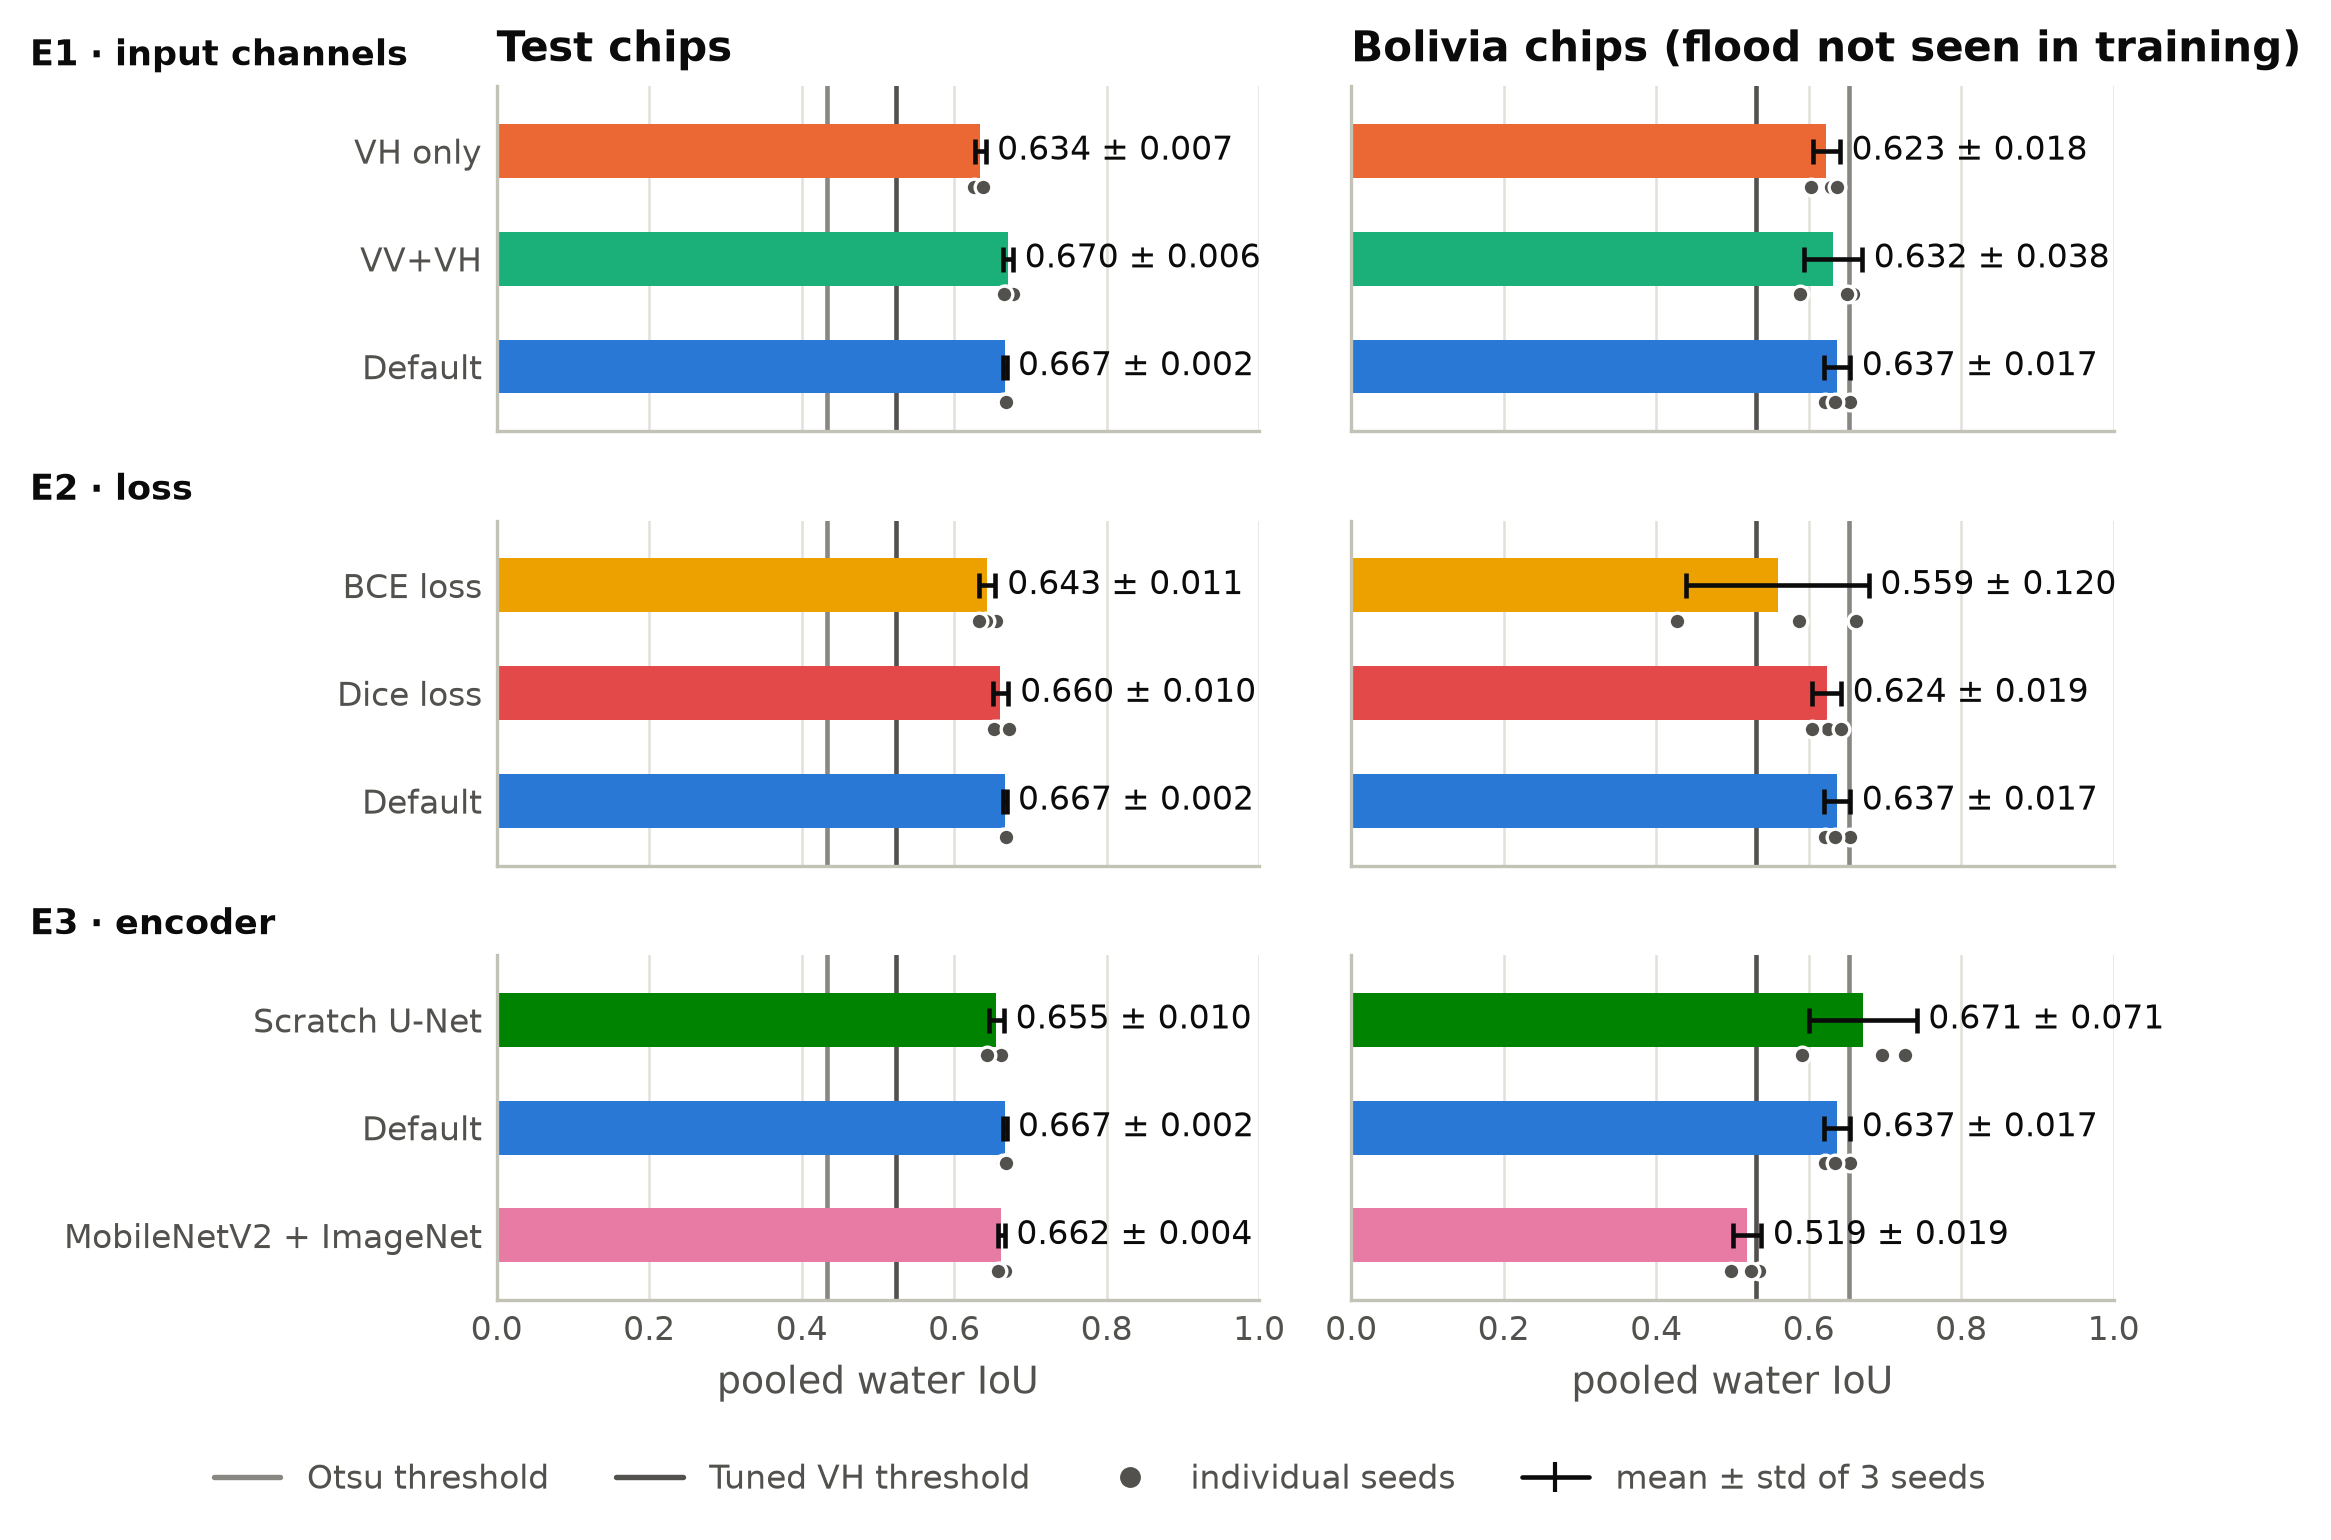

In [6]:
display(Image(filename=str(make_figures.fig_ablations())))
plt.close("all")

## 5. How much do the scores depend on which chips are in the test set?

The standard deviation over seeds says how much a result moves when training is repeated. It says nothing about the luck of the draw in the evaluation data. For that, the chips of a split are resampled with replacement 10,000 times and the pooled IoU is recomputed each time (a chip-level bootstrap). The interval below covers 95% of the resampled scores.

In [7]:
rows = []
for run_id in ["R00", "R00b", *runs_of("Default")]:
    row = {"Run": run_id, "Config": runs.set_index("Run ID").loc[run_id, "Config"]}
    for split in ("test", "bolivia"):
        low, high = analysis.bootstrap_interval(run_id, split)
        iou = runs.set_index("Run ID").loc[run_id, "Test IoU" if split == "test" else "Bolivia IoU"]
        row[f"{split} IoU"] = iou
        row[f"{split} 95% interval"] = f"{low:.3f} to {high:.3f}"
    rows.append(row)
intervals = pd.DataFrame(rows).set_index("Run")
intervals.to_csv(ROOT / "results" / "bootstrap_intervals.csv")
intervals

,Config,test IoU,test 95% interval,bolivia IoU,bolivia 95% interval
Run,,,,,
R00,Otsu (E0),0.4334,0.324 to 0.530,0.6529,0.444 to 0.773
R00b,Tuned VH threshold,0.5240,0.412 to 0.610,0.5314,0.376 to 0.623
R01,Default,0.6681,0.547 to 0.759,0.6547,0.440 to 0.768
R02,Default,0.6640,0.539 to 0.757,0.6213,0.409 to 0.753
R03,Default,0.6674,0.553 to 0.755,0.6347,0.414 to 0.755


The same resampling, applied to the *difference* between a U-Net and a threshold rule on the same chips, shows whether the U-Net's lead survives a different draw of chips:

In [8]:
rows = []
for unet in runs_of("Default"):
    for baseline in ("R00", "R00b"):
        for split in ("test", "bolivia"):
            diff, low, high, share = analysis.bootstrap_difference(unet, baseline, split)
            rows.append({"U-Net": unet, "Baseline": baseline, "Split": split, "IoU difference (U-Net - baseline)": diff,
                         "95% interval": f"{low:+.3f} to {high:+.3f}", "Resamples in which the U-Net wins": share})
diffs = pd.DataFrame(rows)
diffs.to_csv(ROOT / "results" / "bootstrap_differences.csv", index=False)
diffs.set_index(["Split", "Baseline", "U-Net"]).sort_index()

IoU difference (U-Net - baseline)      95% interval  Resamples in which the U-Net wins
Split   Baseline U-Net                                                                                        
bolivia R00      R01                               0.0018  -0.061 to +0.056                             0.4289
                 R02                              -0.0316  -0.130 to +0.048                             0.2259
                 R03                              -0.0183  -0.080 to +0.038                             0.2128
        R00b     R01                               0.1233  +0.059 to +0.152                             0.9983
                 R02                               0.0898  -0.000 to +0.146                             0.9738
                 R03                               0.1032  +0.025 to +0.146                             0.9904
test    R00      R01                               0.2347  +0.158 to +0.314                             1.0000
                 R02                               0.2306  +0.151 to +0.310                             1.0000
                 R03                               0.2340  +0.162 to +0.311                             1.0000
        R00b     R01                               0.1442  +0.114 to +0.181                             1.0000
                 R02                               0.1401  +0.105 to +0.179                             1.0000
                 R03                               0.1435  +0.112 to +0.183                             1.0000

## 6. Test against Bolivia (RQ4)

In [9]:
rq4 = pd.DataFrame({
    "Test IoU": s["Test IoU mean"], "Bolivia IoU": s["Bolivia IoU mean"],
    "Bolivia - test": s["Bolivia IoU mean"] - s["Test IoU mean"],
    "Test mean per-chip IoU": s["Test mean per-chip IoU mean"], "Bolivia mean per-chip IoU": s["Bolivia mean per-chip IoU mean"],
    "Test recall": s["Test recall mean"], "Bolivia recall": s["Bolivia recall mean"],
    "Test precision": s["Test precision mean"], "Bolivia precision": s["Bolivia precision mean"],
})
rq4

,Test IoU,Bolivia IoU,Bolivia - test,Test mean per-chip IoU,Bolivia mean per-chip IoU,Test recall,Bolivia recall,Test precision,Bolivia precision
Config,,,,,,,,,
Otsu (E0),0.4334,0.6529,0.2195,0.2604,0.4423,0.8094,0.8594,0.4827,0.7310
Tuned VH threshold,0.5240,0.5314,0.0075,0.2789,0.3223,0.6371,0.5773,0.7468,0.8700
Default,0.6665,0.6369,-0.0296,0.3979,0.3819,0.7670,0.6991,0.8364,0.8780
VH only,0.6345,0.6232,-0.0113,0.3583,0.3817,0.7299,0.6764,0.8293,0.8888
VV+VH,0.6703,0.6322,-0.0381,0.4026,0.3934,0.7570,0.6958,0.8544,0.8738
BCE loss,0.6433,0.5593,-0.0839,0.3719,0.3378,0.7245,0.6030,0.8528,0.8908
Dice loss,0.6604,0.6237,-0.0367,0.3936,0.3714,0.7655,0.6925,0.8279,0.8633
Scratch U-Net,0.6554,0.6714,0.0160,0.3934,0.4143,0.7897,0.7590,0.7941,0.8569
MobileNetV2 + ImageNet,0.6620,0.5193,-0.1427,0.4003,0.3539,0.7524,0.5794,0.8464,0.8347


## 7. Pixels with a label but no radar value

One test chip has no radar data at all, and a few others have gaps. These pixels count in every score above. The table shows the pooled IoU with and without them.

In [10]:
obs = runs[["Run ID", "Config", "Test IoU", "Test IoU (observed pixels only)", "Bolivia IoU", "Bolivia IoU (observed pixels only)"]].copy()
obs["Test gain"] = obs["Test IoU (observed pixels only)"] - obs["Test IoU"]
obs["Bolivia gain"] = obs["Bolivia IoU (observed pixels only)"] - obs["Bolivia IoU"]
obs.groupby("Config", sort=False)[["Test IoU", "Test IoU (observed pixels only)", "Test gain", "Bolivia IoU",
                                   "Bolivia IoU (observed pixels only)", "Bolivia gain"]].mean()

,Test IoU,Test IoU (observed pixels only),Test gain,Bolivia IoU,Bolivia IoU (observed pixels only),Bolivia gain
Config,,,,,,
Otsu (E0),0.4334,0.4381,0.0047,0.6529,0.6562,0.0032
Default,0.6665,0.6781,0.0115,0.6369,0.6437,0.0069
VH only,0.6345,0.6455,0.0110,0.6232,0.6284,0.0053
VV+VH,0.6703,0.6821,0.0118,0.6322,0.6389,0.0066
BCE loss,0.6433,0.6547,0.0114,0.5593,0.5656,0.0063
Dice loss,0.6604,0.6718,0.0114,0.6237,0.6308,0.0071
Scratch U-Net,0.6554,0.6662,0.0108,0.6714,0.6775,0.0061
MobileNetV2 + ImageNet,0.6620,0.6736,0.0116,0.5193,0.5235,0.0042
Tuned VH threshold,0.5240,0.5327,0.0087,0.5314,0.5346,0.0032


## 8. The best U-Net, chosen on validation

The error analysis, the qualitative figure and the inference demo need one model. It is chosen by validation IoU; test scores play no part in the choice.

In [11]:
best = analysis.write_best_run(runs)
ranking = runs[~runs["Run ID"].isin(analysis.THRESHOLD_RUNS)].sort_values("Val IoU (best)", ascending=False)
print(json.dumps(best, indent=2))
ranking[["Run ID", "Config", "Seed", "Val IoU (best)"]].head(5).set_index("Run ID")

{
  "run_id": "R19",
  "config": "MobileNetV2 + ImageNet",
  "seed": 0,
  "val_iou": 0.6697116933744752,
  "chosen_by": "highest validation IoU among all finished U-Net runs; test scores were not consulted"
}


,Config,Seed,Val IoU (best)
Run ID,,,
R19,MobileNetV2 + ImageNet,0,0.6697
R20,MobileNetV2 + ImageNet,1,0.6675
R09,VV+VH,2,0.6613
R21,MobileNetV2 + ImageNet,2,0.6558
R16,Scratch U-Net,0,0.6493
